# 3 · Prediction intervals

About 70% of the rating's variance is match noise, so a point forecast hides most of the
story: "6.4" really means "probably somewhere between 5.4 and 7.4". This notebook builds
intervals with split conformal prediction and checks them on the held-out test week.

## Split conformal prediction in three steps

1. Take predictions on data the model has not seen: the walk-forward out-of-fold predictions
   from the four validation weeks.
2. Compute their absolute errors and take the ⌈(n + 1) · 0.9⌉-th smallest one. Call it q.
3. The interval ŷ ± q then covers at least 90% of new ratings, as long as the calibration
   errors and the new errors are exchangeable. Nothing is assumed about the shape of the
   error distribution.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from player_rating.config import FIGURES_DIR, METRICS_DIR, MODELS_DIR

summary = json.loads((METRICS_DIR / "run_summary.json").read_text())
print("selected model:", summary["selected_model"])
print("calibration errors:", summary["calibration_errors"])
pd.Series(summary["conformal_half_widths"]).round(3).to_frame("half-width (rating points)")

selected model: LightGBM, v2 features
calibration errors: 14040


,half-width (rating points)
80%,0.813
90%,1.049


## Coverage on the test week

level,0.8,0.9
group,,
Defender,0.803,0.891
Forward,0.796,0.887
Goalkeeper,0.858,0.930
Midfielder,0.816,0.918
all,0.810,0.902


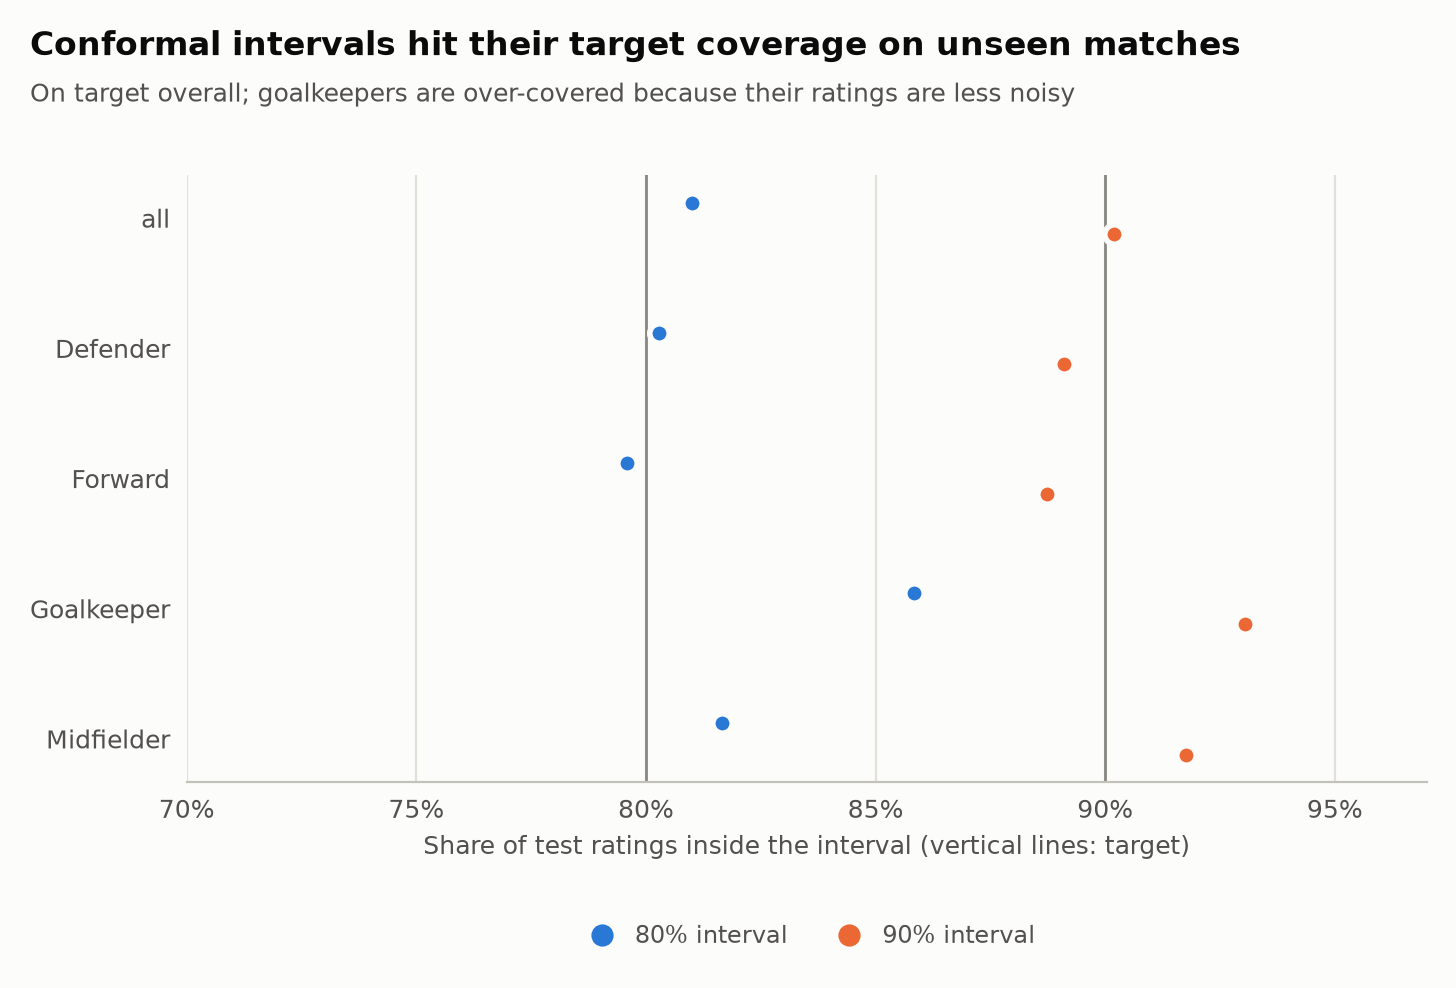

In [2]:
coverage = pd.read_csv(METRICS_DIR / "conformal_coverage.csv")
display(coverage.pivot(index="group", columns="level", values="coverage").round(3))
display(Image(FIGURES_DIR / "interval_coverage_light.png", width=720))

Overall coverage is on target: 81.0% for the 80% interval and 90.2% for the 90% interval.
The half-widths of ±0.81 and ±1.05 are only 2–3% wider than what a forecaster that knew every
player's true level would need under Gaussian match noise (±0.80 and ±1.02).

By position, coverage is less even:

- goalkeepers' ratings are less noisy, so their intervals are too wide (85.8% and 93.1%);
- forwards' intervals are slightly too narrow (79.6% and 88.7%).

Split conformal guarantees coverage on average, not for every subgroup. Calibrating each
position separately (Mondrian conformal), or scaling every interval by a per-group noise
estimate, would fix this. It is the next step on the roadmap.

## What a forecast looks like

In [3]:
predictions = pd.read_parquet(MODELS_DIR / "test_predictions.parquet")
model, q90 = summary["selected_model"], summary["conformal_half_widths"]["90%"]
sample = predictions.sample(8, random_state=1)
pd.DataFrame(
    {
        "player": sample["player_name"],
        "opponent": sample["opponent_team"],
        "forecast": sample[model].round(2),
        "90% interval": [f"{p - q90:.1f} to {p + q90:.1f}" for p in sample[model]],
        "actual": sample["player_rating"],
    }
)

,player,opponent,forecast,90% interval,actual
24442,Mohammed Al-Shahrani,Spain,6.44,5.4 to 7.5,6.5
25535,Hassan Al-Zahrani,Spain,6.34,5.3 to 7.4,6.6
23937,Abdulrahman Al-Salem,Cameroon,5.98,4.9 to 7.0,6.2
24551,Radamel Rios,Cameroon,6.87,5.8 to 7.9,8.0
21122,Keanu Wright,France,6.32,5.3 to 7.4,6.6
25039,Dusan Terzic,Mexico,5.97,4.9 to 7.0,6.7
21830,Cristiano Jota,Panama,5.93,4.9 to 7.0,6.5
23968,Gianluca Tapia,Switzerland,5.93,4.9 to 7.0,6.0


## Limitations

- **Exchangeability over time.** The calibration errors come from earlier weeks. If the noise
  level drifts, for example in knockout matches, coverage drifts with it. Here it held on the
  test week.
- **Wide by nature.** The intervals are wide because the rating itself is noisy, not because
  the model is unsure about the player. Even a forecaster that knew every player's true level
  would need about ±0.80 (80%) and ±1.02 (90%), given match noise with σ ≈ 0.62 and assuming
  it is Gaussian. The conformal half-widths above are only a few percent wider than that.